In [240]:
''' 
Simulation class creation for the simulation of EAB dynamic network in Maritime Canada

'''
import networkx as nx
import simpy
import pandas as pd
import random

In [241]:
import os

os.chdir('/..')
os.chdir('Users/alexp/OneDrive - University of New Brunswick/Grad Studies/Modelling_transport_pathways/Clean_data_sets')

os.getcwd()

'C:\\Users\\alexp\\OneDrive - University of New Brunswick\\Grad Studies\\Modelling_transport_pathways\\Clean_data_sets'

In [242]:
#Initial infected(I) vs susceptible(S) state 
def initial_state(G):
        state = {}
        for node in G.nodes:
            if node == 'Edmunston':
                state[node] = 'I'
            elif node == 'Bedford':
                state[node] = 'I'
            elif node == 'Fredericton':
                state[node] = 'I'
            elif node == 'Moncton':
                state[node] = 'I'
            elif node == 'Oromocto':
                state[node] = 'I'
            else:
                state[node] = 'S'
        nx.set_node_attributes(G,state,'State')
        return state

In [243]:
#test initial_state
#initial_state(G)

In [331]:
def state_transition(G, current_state):
    #The first generalization is that mostThe Þrst generalization is that a majority of campground visits involve relatively short travel distances (<100 km, which is usually a <2-h drive fromhome) Koch et al. 2012 
    next_state={}
    degree={}
    iorigin_degree={}
    
    #Per capita value is a source of number of reservations taken from a national system 
    per_capita_value=0.0047
    #Firewood source(outside park:0.25, from home:0.17,cut of collected from another area:0.14)Jacobi et al. 2011, and Percent of live borers found in wood(0.23) Haack et al. 2010
    prob_infested_wood=(0.25+0.17+0.14)*0.23
    #Iterate through each node splitting the two by infected and uninfected nodes 
    for node in G.nodes:
        #if the node is infected, print the number of campers leaving the campground with infested wood/year(per capita value) is calculated, and calculate the total campground pull value from all campgrounds(in degree)
        
        if current_state[node] == 'I':
            #number of infected campers from campgrounds
            nx.set_node_attributes(G,{node:G.nodes[node]['Population']*(per_capita_value*prob_infested_wood)},'Infected_camper')
            Inf_camper = nx.get_node_attributes(G,'Infected_camper')
            
            #Get total campground pull from all neighbour nodes
            degree[node]= G.degree(node, weight='Campground_pull')
            nx.set_node_attributes(G, degree,'in_degree')
            
        #iCampground_pull={}
            inode_degree={}
            for neighbor in G.neighbors(node):
                
                
                #ipull_dict={}
                ipull = (G.nodes[neighbor]['Sites']/G.edges[neighbor,node]['Distance_Km'])/degree[node]
                #ipull_dict['Campground_pull']=ipull
                #iCampground_pull[node,neighbor]=ipull_dict
                
                inode_degree[neighbor]=ipull
                iorigin_degree[node]=inode_degree
        
    for node in G.nodes:
        if current_state[node] == 'I':
            num_inf_camper=int(G.nodes[node]['Infected_camper'])
            
            
        
            #G.edges[node]['Campground_pull']
            #random.choices(degree[node])
    #return next_state
    return Inf_camper, degree, iorigin_degree
    #return removed: Pull

#if the node is susceptible pull data from the neighbours nodes
        #elif current_state[node] == 'S':
            #Campground_pull={}
            #node_degree={}
            #origin_degree={}
            #Get data from each neighbour of the node to calculate pull number of campsites/distance between nodes to get campground pull value
            #for neighbor in G.neighbors(node):
                
                
                #pull_dict={}
                #pull = (G.nodes[node]['Sites']/G.edges[node,neighbor]['Distance_Km'])/G.nodes[neighbor]['in_degree']
                #pull_dict['Campground_pull']=pull
                #Campground_pull[node,neighbor]=pull_dict
                
                #node_degree[node]=pull
                #origin_degree[neighbor]=node_degree
                
                
            #nx.set_edge_attributes(G, Campground_pull)
            #Pull = nx.get_edge_attributes(G, 'Campground_pull')

In [332]:
#test state transition
test_state = initial_state(G)
state_transition(G, test_state)

({'Bedford': 244.03938216000003,
  'Edmunston': 7.316380960000001,
  'Fredericton': 35.2440592,
  'Moncton': 43.51872504000001,
  'Oromocto': 5.583235280000001},
 {'Bedford': 150.19403641301494,
  'Edmunston': 94.20884174656089,
  'Fredericton': 114.24302368997486,
  'Moncton': 202.08509091040472,
  'Oromocto': 116.95876227249009},
 {'Bedford': {'ADDA Fundy Tides CG- City': 0.0010382790750059006,
   'Adventures East Campground & Cottages': 0.001701005106846649,
   'All Done Camping': 0.0009764233695178017,
   'All Points East Campground': 0.000677737798699277,
   'Amherst Shore Provincial Park': 0.0014605891398619486,
   'Anchorage Provincial Park': 0.0016330864215510466,
   'Arm of Gold Campgrounds': 0.0,
   'Armstrong Brook-Mount Carleton Provincial Park': 0.0010921694496169206,
   'Baddeck Cabot Trail Campground': 0.0037939215028118703,
   'Battery Provincial Park': 0.0011286636803758269,
   'Bayside RV Campground': 0.0,
   'Bear Falls Wilderness Campground': 0.001316779576378097,
 

In [154]:
#import dataframes
#gravity_df=pd.read_csv('Campground_origin_data_raw.csv',index_col=0)
edge_df=pd.read_csv('edge_dataframe.csv',index_col=0)
node_df=pd.read_csv('node_dataframe.csv',index_col=0)
#convert dataframe to edgelist
G=nx.from_pandas_edgelist(edge_df,source='Origin',target='Campground',edge_attr=['Distance_Km'])
#add node attributes to edgelist
nx.set_node_attributes(G,dict(zip(node_df['Name'],node_df['Population'])),'Population')
nx.set_node_attributes(G, dict(zip(node_df['Name'],node_df['Sites'])),'Sites')

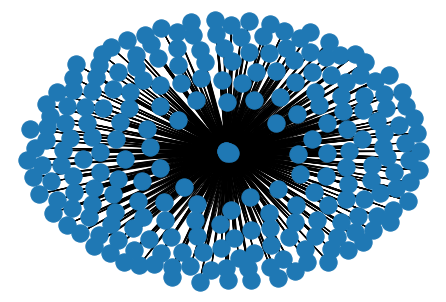

In [34]:
#The first generalization is that that a majority of campground visits involve relatively short travel distances (<100 km, which is usually a <2-h drive fromhome) Koch et al. 2012 
current_state = G  

next_state={}
per_capita_value=0.0047
#Firewood source(outside park:0.25, from home:0.17,cut of collected from another area:0.14)Jacobi et al. 2011, and Percent of live borers found in wood(0.23) Haack et al. 2010
prob_infested_wood=(0.25+0.17+0.14)*0.23
#list through going node by node to check for the current state to see the probability of a 
for node in G.nodes:
    Infected_camper=[]
    if current_state[node] == 'I':
        nx.set_node_attributes(G,{node:G.nodes[node]['Population']*(per_capita_value*prob_infested_wood)},'Infected_camper')
        nx.get_node_attributes(node,'Infected_camper')
    #if current_state[node] == 'S':
#for node in G.nodes:
    #for node in G.edges:
    #nx.get_edge_attributes
    

In [167]:
import networkx as nx

sim=simulation_EAB()
sim.initial_state(G)

TypeError: __init__() missing 1 required positional argument: 'G'

In [18]:
#nx.get_node_attributes(G,'Sites')
#dict(zip(node_df['Name'],node_df['Population']))
#pd.Series(node_df['Population'],index=node_df.Name)
G.nodes['Fredericton']['Population']

58220

TypeError: draw_networkx_edge_labels() missing 1 required positional argument: 'pos'

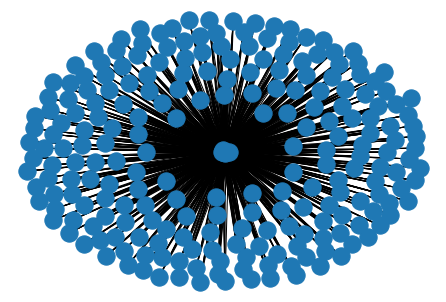

In [17]:
'Draw Graph'
#need to add positions to the edgelist of nodes
nx.draw(G)
edge_label=nx.get_edge_attributes(G,'Distance_km')
node_label=nx.get_edge_attributes(G,'campsites')
nx.draw_networkx_edge_labels(G, edge_labels=edge_label)
